In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split

from sklearn.metrics import(
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

In [2]:
df = pd.read_csv('../data/processed/churn_engineered.csv')

X = df.drop(columns=['Churn'])
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2,
    random_state=42,
    stratify=y
)

print("Test customers:", len(X_test))
print("Actual churners:", y_test.sum())
print("Actual non churners:", (y_test == 0).sum())

Test customers: 1409
Actual churners: 374
Actual non churners: 1035


In [3]:
final_model = joblib.load('../models/churn_model_final.pkl')

print(final_model)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])


In [4]:
y_proba = final_model.predict_proba(X_test)[:,1]

print("First 10 churn probabilities:")
print(y_proba[:10])

print("number of predictions:", len(y_proba))

First 10 churn probabilities:
[0.11698811 0.84617382 0.12890777 0.60943709 0.08144982 0.78359029
 0.6720037  0.2607729  0.01395821 0.54969286]
number of predictions: 1409


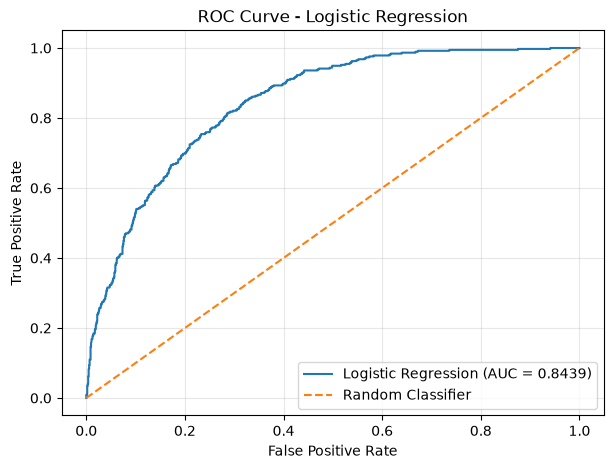

In [8]:
fpr, tpr, threshold = roc_curve(y_test, y_proba)

roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f'Logistic Regression (AUC = {roc_auc:.4f})'
)

plt.plot(
    [0,1],[0,1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel("False Positive Rate")
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The ROC curve shows that the model distinguishes churners from non churners reasonably well with an AUC of 0.8439. Its performance is much better than random guessing (AUC = 0.5)

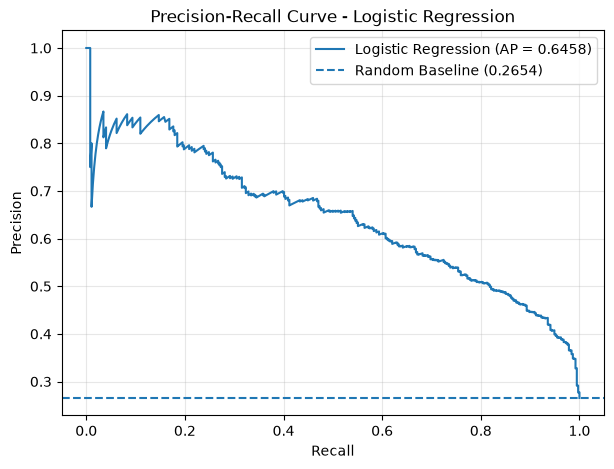

Average Precision: 0.6458


In [9]:
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_proba)

ap = average_precision_score(y_test, y_proba)

baseline = y_test.mean()

plt.figure(figsize=(7,5))

plt.plot(
    recall, precision,
    label=f'Logistic Regression (AP = {ap:.4f})'
)

plt.axhline(
    y=baseline,
    linestyle='--',
    label=f'Random Baseline ({baseline:.4f})'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Logistic Regression')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Average Precision:", round(ap, 4))

Logistic Regression model achieved an Average Precision of 0.6458, substantially outperforming the random baseline of 0.2654. The curve shows that precision decreases as recall increases, reflecting the trade-off between identifying more churners and generating false alerts.

In [10]:
risk_df = pd.DataFrame({
    'Actual_Churn': y_test.to_numpy(),
    'Churn_Probabilty': y_proba
})

risk_df = risk_df.sort_values(
    by='Churn_Probabilty',
    ascending=False
).reset_index(drop=True)

display(risk_df.head(10))

,Actual_Churn,Churn_Probabilty
0,1,0.962032
1,1,0.953044
2,1,0.952239
3,0,0.950355
4,1,0.949747
5,0,0.949176
6,1,0.946831
7,1,0.946303
8,1,0.945748
9,1,0.945220


In [40]:
# Number of customers and churners
total_customers = len(risk_df)
total_churners = risk_df['Actual_Churn'].sum()

# Number of customers included as we move down the ranking
risk_df['Customers_Targeted'] = np.arange(1, total_customers + 1)

# Cumulative number of actual churners captured
risk_df['Churners_Captured'] = risk_df['Actual_Churn'].cumsum()

# Percentage of customers targeted
risk_df['Customer_Fraction'] = (
    risk_df['Customers_Targeted'] / total_customers
)

# Percentage of actual churners captured
risk_df['Cumulative_Gain'] = (
    risk_df['Churners_Captured'] / total_churners
)

# Lift compared with random selection
risk_df['Lift'] = (
    risk_df['Cumulative_Gain'] / risk_df['Customer_Fraction']
)

display(risk_df.head(10))

,Actual_Churn,Churn_Probabilty,Churners_Captured,Customers_Targeted,Customer_Fraction,Cumulative_Gain,Lift
0,1,0.962032,1,1,0.000710,0.002674,3.767380
1,1,0.953044,2,2,0.001419,0.005348,3.767380
2,1,0.952239,3,3,0.002129,0.008021,3.767380
3,0,0.950355,3,4,0.002839,0.008021,2.825535
4,1,0.949747,4,5,0.003549,0.010695,3.013904
5,0,0.949176,4,6,0.004258,0.010695,2.511586
6,1,0.946831,5,7,0.004968,0.013369,2.690985
7,1,0.946303,6,8,0.005678,0.016043,2.825535
8,1,0.945748,7,9,0.006388,0.018717,2.930184
9,1,0.945220,8,10,0.007097,0.021390,3.013904


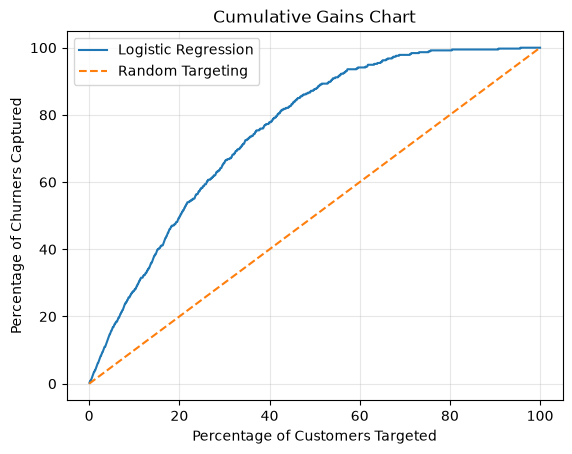

In [43]:
plt.plot(
    risk_df['Customer_Fraction'] * 100,
    risk_df['Cumulative_Gain'] * 100,
    label='Logistic Regression'
)

plt.plot(
    [0,100], [0,100],
    linestyle='--',
    label='Random Targeting'
)

plt.xlabel('Percentage of Customers Targeted')
plt.ylabel('Percentage of Churners Captured')
plt.title('Cumulative Gains Chart')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The model captures approximately 50% of actual churners by targeting the top 20% highest-risk customers, compared with 20% expected from random targeting. This shows effective prioritization of potential churners.

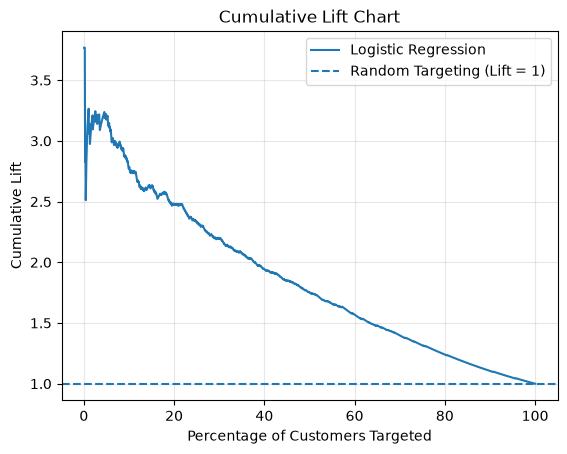

In [46]:
plt.plot(
    risk_df['Customer_Fraction'] * 100,
    risk_df['Lift'],
    label='Logistic Regression'
)

plt.axhline(
    y=1,
    linestyle='--',
    label='Random Targeting (Lift = 1)'
)

plt.xlabel('Percentage of Customers Targeted')
plt.ylabel('Cumulative Lift')
plt.title('Cumulative Lift Chart')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

At 20% targeting, the model achieves approximately 2.5× lift over random selection. Lift gradually decreases as lower-risk customers are included, reaching 1 at 100% targeting.

In [47]:
target_percentages = [0.10, 0.20, 0.30]

target_results = []

for pct in target_percentages:
    n = int(np.ceil(total_customers * pct))
    top_customers = risk_df.head(n)
    captured = top_customers['Actual_Churn'].sum()

    gain = captured/total_churners
    actual_fraction = n/total_customers
    lift = gain/actual_fraction

    target_results.append({
        'Targeted (%)': round(actual_fraction * 100, 2),
        'Customers Contacted': n,
        'Churners Captured': captured,
        'Churners Captured (%)': round(gain * 100, 2),
        'Lift': round(lift, 2)
    })

target_df = pd.DataFrame(target_results)

display(target_df)

,Targeted (%),Customers Contacted,Churners Captured,Churners Captured (%),Lift
0,10.01,141,104,27.81,2.78
1,20.01,282,185,49.47,2.47
2,30.02,423,246,65.78,2.19


The model successfully identifies customers who are more likely Churn. By focusing on just the top 20% highest-risk customers, the company could reach nearly 50% of all customers who actually left, making this approach 2.47 times more effective than selecting customers randomly. Increasing the target group to 30% would cover nearly 66% of customers who left. 

These results show that the model can help businesses prioritize customers who need attention, saving time and resources while supporting better customer retention efforts.